<a href="https://colab.research.google.com/github/oktvindh/Praktikum-Machine-Learning/blob/main/praktikumBAB2NaiveBayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import learning_curve
# Ganti DecisionTreeClassifier dengan GaussianNB
from sklearn.naive_bayes import GaussianNB

In [ ]:
# 1. Import dataset Churn
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [ ]:
# 2. Preprocessing Data
data = df.copy()
data = data.drop(columns=["customerID"])

data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"],
    errors="coerce"
)

# Isi missing value TotalCharges dengan median
data["TotalCharges"] = data["TotalCharges"].fillna(
    data["TotalCharges"].median()
)

In [ ]:
# 3. Pisahkan fitur dan target
X = data.drop(columns=["Churn"])
y = data["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Mengubah data kategorikal menjadi numerik
X = pd.get_dummies(X, drop_first=True)

In [ ]:
# 4. Split data train dan test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
# 5. Inisialisasi Model Naive Bayes
model = GaussianNB()

In [ ]:
# 6. Hitung Learning Curve untuk Naive Bayes
train_sizes, train_scores, val_scores = learning_curve(
    model,
    X_train,
    y_train,
    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 6),
    scoring="accuracy"
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

print("=" * 50)
print("Hasil Evaluasi Naive Bayes:")
print("Skor train pada ukuran data terbesar :", round(train_mean[-1], 3))
print("Skor validasi pada ukuran data terbesar :", round(val_mean[-1], 3))
print("Gap (indikasi overfitting jika besar) :", round(train_mean[-1] - val_mean[-1], 3))
print("=" * 50)

Hasil Evaluasi Naive Bayes:
Skor train pada ukuran data terbesar : 0.665
Skor validasi pada ukuran data terbesar : 0.663
Gap (indikasi overfitting jika besar) : 0.002


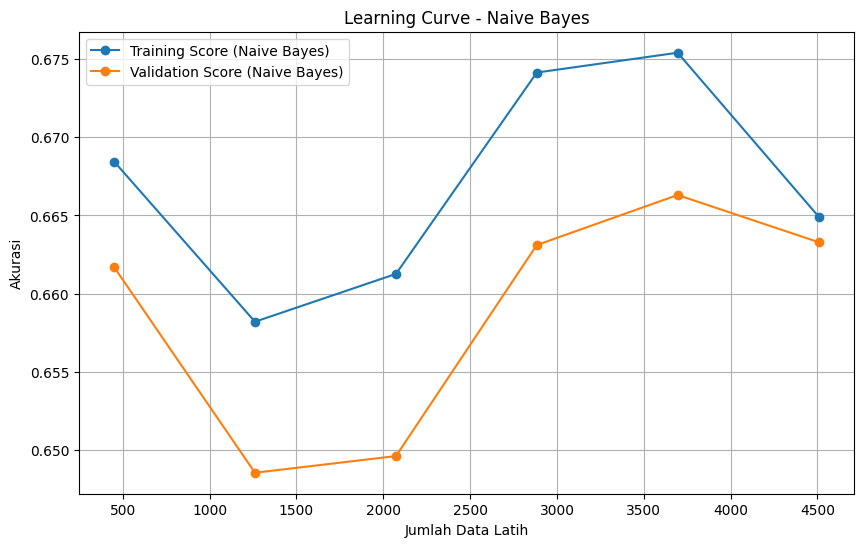

In [ ]:
# 7. Visualisasi Learning Curve Naive Bayes
plt.figure(figsize=(10, 6))

plt.plot(
    train_sizes,
    train_mean,
    '-o',
    label='Training Score (Naive Bayes)'
)

plt.plot(
    train_sizes,
    val_mean,
    '-o',
    label='Validation Score (Naive Bayes)'
)

plt.xlabel('Jumlah Data Latih')
plt.ylabel('Akurasi')
plt.title('Learning Curve - Naive Bayes')
plt.legend()
plt.grid(True)

plt.show()